In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
import yfinance as yf

# Value at Risk with Backtesting

## Data and Portfolio Returns

In [6]:
tickers = ["NESN.SW", "NOVN.SW", "UBSG.SW", "ZURN.SW"]
prices = yf.download(tickers, start="2015-01-01", auto_adjust=True)["Close"]
prices = prices.dropna()

print(prices.tail())
print(prices.shape)

returns = prices.pct_change().dropna()
weights = np.array([0.25, 0.25, 0.25, 0.25])
port_returns = (returns*weights).sum(axis=1)

print(port_returns.describe())

[*********************100%***********************]  4 of 4 completed

Ticker        NESN.SW     NOVN.SW    UBSG.SW     ZURN.SW
Date                                                    
2026-11-03  84.410004  131.500000  39.470001  625.400024
2026-11-04  85.900002  134.259995  41.279999  637.599976
2026-11-05  87.230003  134.119995  39.889999  643.799988
2026-11-06  85.849998  133.080002  39.540001  630.200012
2026-11-09  86.129997  133.460007  39.959999  632.599976
(2980, 4)
count    2979.000000
mean        0.000452
std         0.010304
min        -0.107560
25%        -0.004364
50%         0.000673
75%         0.005698
max         0.079883
dtype: float64


## VaR and Expected Shortfall

In [7]:
alpha = 0.01

# 1) historic simulation
q = port_returns.quantile(alpha)
var_hist = -q
es_hist = -port_returns[port_returns <= q].mean()

# 2) parametic
mu = port_returns.mean()
sigma = port_returns.std()
z = norm.ppf(alpha)
var_param = -(mu + z * sigma)
es_param = -mu + sigma * norm.pdf(z) / alpha

print(f"Historical  VaR 99%: {var_hist:.2%}   ES 99%: {es_hist:.2%}")
print(f"Parametric  VaR 99%: {var_param:.2%}   ES 99%: {es_param:.2%}")

Historical  VaR 99%: 3.18%   ES 99%: 4.48%
Parametric  VaR 99%: 2.35%   ES 99%: 2.70%


Excess kurtosis: 10.24   (Normal distribution = 0)


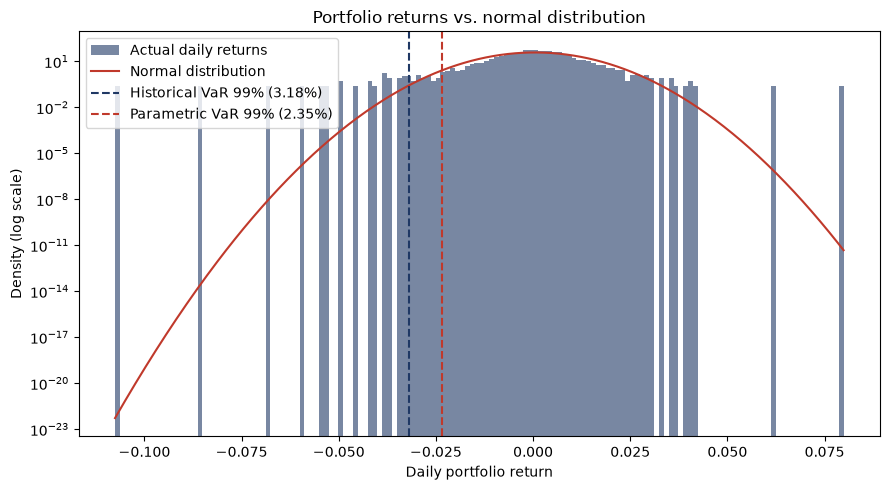

In [8]:
print(f"Excess kurtosis: {port_returns.kurt():.2f}   (Normal distribution = 0)")

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(port_returns, bins=150, density=True, color="#1F3864", alpha=0.6,
        label="Actual daily returns")
x = np.linspace(port_returns.min(), port_returns.max(), 500)
ax.plot(x, norm.pdf(x, mu, sigma), color="#C0392B", linewidth=1.5,
        label="Normal distribution")
ax.axvline(-var_hist, color="#1F3864", linestyle="--",
           label=f"Historical VaR 99% ({var_hist:.2%})")
ax.axvline(-var_param, color="#C0392B", linestyle="--",
           label=f"Parametric VaR 99% ({var_param:.2%})")

ax.set_yscale("log")
ax.set_xlabel("Daily portfolio return")
ax.set_ylabel("Density (log scale)")
ax.set_title("Portfolio returns vs. normal distribution")
ax.legend()

fig.tight_layout()
fig.savefig("return_distribution.png", dpi=200)
plt.show()